### LSTM Forecasting

**What is LSTM?** A deep learning model for sequences. It reads the last 30 days of AQI and learns
patterns (trend, weekly and seasonal ups and downs) to predict the next 7 days.

**Setup (same fair test as ARIMA and Prophet):**
- Last 28 days are the test set; training data is everything before it.
- Forecast 7 days at a time, 4 times. For each forecast the model sees the **real** last 30 days.
- Same metrics (RMSE, MAE) and same naive baseline.

**Scaling:** neural networks learn better when values are small, so AQI is scaled to 0-1
using only the **training** data (so no information leaks from the test period).

In [11]:
import os, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

In [8]:
clean = pd.read_csv("../01_Data/processed/cleaned_data.csv", parse_dates=["Date"])

In [13]:
clean = pd.read_csv("../01_Data/processed/cleaned_data.csv", parse_dates=["Date"])
MAIN = ["Delhi", "Lucknow", "Bengaluru", "Chennai", "Hyderabad"]
TEST_DAYS, LOOKBACK, HORIZON = 28, 30, 7

In [3]:
def get_series(city):
    s = clean[clean["City"] == city].set_index("Date")["AQI"].sort_index()
    s = s.asfreq("D").interpolate(limit=7)
    missing = s.isna()
    if missing.any():
        s = s.loc[missing[missing].index.max() + pd.Timedelta(days=1):]
    s = s.asfreq("D")
    s.index = pd.DatetimeIndex(s.index, freq="D")
    return s

In [4]:
def metrics(actual, pred):
    err = actual - pred
    return {"RMSE": round(float(np.sqrt((err ** 2).mean())), 1),
            "MAE": round(float(err.abs().mean()), 1)}

def naive_forecast(train, test, horizon=7):
    last, preds = train.iloc[-1], []
    for i in range(0, len(test), horizon):
        chunk = test.iloc[i:i + horizon]
        preds.append(pd.Series(last, index=chunk.index))
        last = chunk.iloc[-1]
    return pd.concat(preds)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


Each training example is 30 days in, next 7 days out. The model is small (32 LSTM units) because we have only about 1,900 days of data per city; a bigger network would just memorize.

In [5]:
def make_sequences(values):
    X, y = [], []
    for i in range(len(values) - LOOKBACK - HORIZON + 1):
        X.append(values[i:i + LOOKBACK])
        y.append(values[i + LOOKBACK:i + LOOKBACK + HORIZON])
    return np.array(X).reshape(-1, LOOKBACK, 1), np.array(y)

def build_model():
    m = keras.Sequential([
        layers.Input(shape=(LOOKBACK, 1)),
        layers.LSTM(32),
        layers.Dropout(0.2),
        layers.Dense(HORIZON),
    ])
    m.compile(optimizer="adam", loss="mse")
    return m

Early stopping stops training when the validation error stops improving (prevents overfitting).
The last 10% of training sequences are kept for validation.

In [6]:
def lstm_rolling(s):
    tr, te = s.iloc[:-TEST_DAYS], s.iloc[-TEST_DAYS:]
    lo, hi = float(tr.min()), float(tr.max())
    full = (s.values - lo) / (hi - lo)          # scaling uses train min/max only
    n_tr = len(tr)

    X, y = make_sequences(full[:n_tr])
    model = build_model()
    stop = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
    model.fit(X, y, epochs=60, batch_size=32, validation_split=0.1,
              callbacks=[stop], verbose=0)

    preds = []
    for i in range(0, TEST_DAYS, HORIZON):
        start = n_tr + i
        window = full[start - LOOKBACK:start].reshape(1, LOOKBACK, 1)
        p = model.predict(window, verbose=0)[0] * (hi - lo) + lo
        preds.append(pd.Series(np.clip(p, 0, None), index=te.index[i:i + HORIZON]))
    return pd.concat(preds), tr, te, model, (lo, hi)

Delhi test

LSTM : {'RMSE': 37.9, 'MAE': 29.5}
Naive: {'RMSE': 46.0, 'MAE': 30.6}


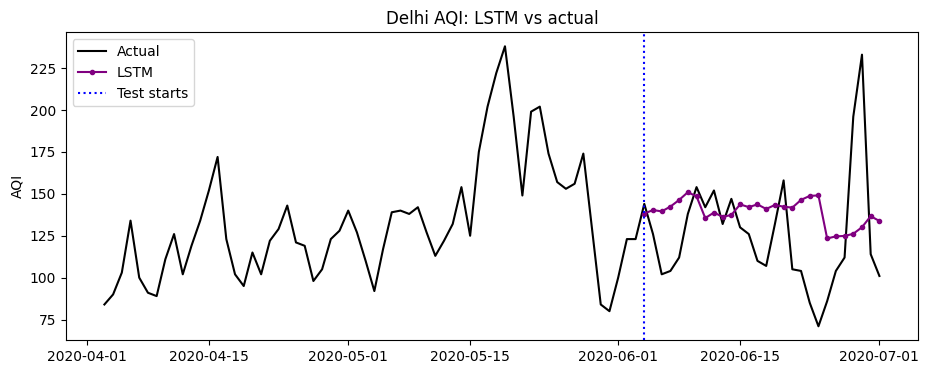

In [14]:
delhi = get_series("Delhi")
pred_l, tr, te, model, (lo, hi) = lstm_rolling(delhi)
print("LSTM :", metrics(te, pred_l))
print("Naive:", metrics(te, naive_forecast(tr, te)))

plt.figure(figsize=(11, 4))
plt.plot(delhi.iloc[-90:], label="Actual", color="black")
plt.plot(pred_l, label="LSTM", color="purple", marker="o", markersize=3)
plt.axvline(te.index.min(), color="blue", linestyle=":", label="Test starts")
plt.title("Delhi AQI: LSTM vs actual")
plt.ylabel("AQI")
plt.legend()
plt.show()

Each city gets its own model. The models and their scaling values are saved in 03_Models, so the backend can load them later.

In [15]:
os.makedirs("../03_Models", exist_ok=True)
rows = []

for city in MAIN:
    try:
        s = get_series(city)
        print(city, "|", len(s), "days")
        if len(s) < 365:
            print("   Skipped: less than 1 year of data")
            continue
        p, tr, te, mdl, (lo, hi) = lstm_rolling(s)
        m, mn = metrics(te, p), metrics(te, naive_forecast(tr, te))
        rows.append({"City": city, "LSTM_RMSE": m["RMSE"], "LSTM_MAE": m["MAE"],
                     "Naive_RMSE": mn["RMSE"]})
        mdl.save(f"../03_Models/lstm_{city}.keras")
        with open(f"../03_Models/lstm_{city}_scale.json", "w") as f:
            json.dump({"lo": lo, "hi": hi, "lookback": LOOKBACK, "horizon": HORIZON}, f)
        print("   done")
    except Exception as e:
        print("   FAILED:", type(e).__name__, "-", str(e)[:150])

lstm_results = pd.DataFrame(rows)
lstm_results.to_csv("../01_Data/processed/lstm_results.csv", index=False)
lstm_results

Delhi | 2009 days
   done
Lucknow | 1497 days
   done
Bengaluru | 1930 days
   done
Chennai | 1279 days
   done
Hyderabad | 1399 days
   done


,City,LSTM_RMSE,LSTM_MAE,Naive_RMSE
0,Delhi,37.2,28.7,46.0
1,Lucknow,45.3,41.1,51.3
2,Bengaluru,13.9,12.0,13.2
3,Chennai,22.7,14.8,26.6
4,Hyderabad,24.4,20.0,15.2


All models in one table. The model with the lowest RMSE for each city is marked as best. A model is only useful if it beats the naive baseline.

In [16]:
comparison = lstm_results.copy()

for name, path, col in [("ARIMA", "arima_results.csv", "RMSE"),
                        ("Prophet", "prophet_results.csv", "Prophet_RMSE")]:
    try:
        r = pd.read_csv("../01_Data/processed/" + path)[["City", col]]
        r.columns = ["City", f"{name}_RMSE"]
        comparison = comparison.merge(r, on="City", how="left")
    except FileNotFoundError:
        print(f"{path} not found, skipping {name}")

rmse_cols = [c for c in ["Naive_RMSE", "ARIMA_RMSE", "Prophet_RMSE", "LSTM_RMSE"] if c in comparison.columns]
model_cols = [c for c in rmse_cols if c != "Naive_RMSE"]
comparison["Best_model"] = comparison[model_cols].idxmin(axis=1).str.replace("_RMSE", "")
comparison["Beats_naive"] = comparison[model_cols].min(axis=1) < comparison["Naive_RMSE"]

comparison = comparison[["City"] + rmse_cols + ["Best_model", "Beats_naive"]]
comparison.to_csv("../01_Data/processed/model_comparison.csv", index=False)
comparison

,City,Naive_RMSE,ARIMA_RMSE,Prophet_RMSE,LSTM_RMSE,Best_model,Beats_naive
0,Delhi,46.0,37.6,49.0,37.2,LSTM,True
1,Lucknow,51.3,39.9,42.7,45.3,ARIMA,True
2,Bengaluru,13.2,13.2,15.2,13.9,ARIMA,False
3,Chennai,26.6,23.9,41.4,22.7,LSTM,True
4,Hyderabad,15.2,16.3,22.1,24.4,ARIMA,False


Comparison graph

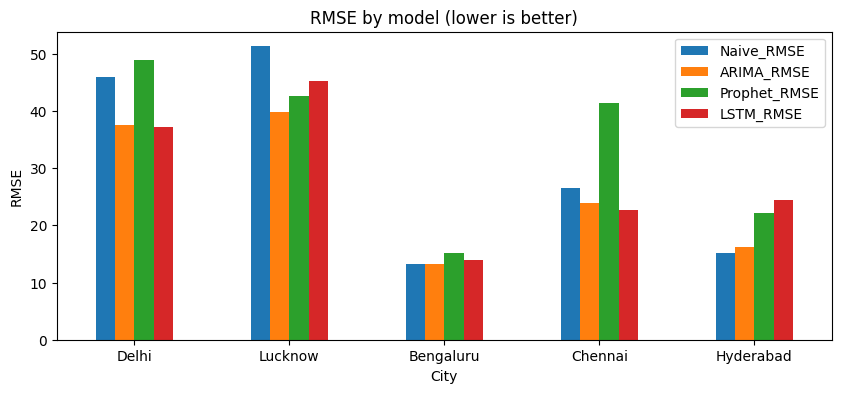

In [17]:
comparison.set_index("City")[rmse_cols].plot(kind="bar", figsize=(10, 4),
                                             title="RMSE by model (lower is better)")
plt.ylabel("RMSE")
plt.xticks(rotation=0)
plt.show()

## Summary of Notebook 6
- LSTM reads the last 30 days and predicts the next 7 days, trained separately for each city.
- Same test as ARIMA and Prophet: last 28 days, 7-day rolling forecast.
- Best model per city (from the table): ____
- LSTM / ARIMA / Prophet beat the naive baseline in ___ of 5 cities.

**Limitations:** the test window is only 28 days, so one unusual week can change the ranking.
LSTM is not retrained during the test; ARIMA and Prophet are updated with new data.

**Next step:** health advisory logic, cigarette meter and the backend.